# 04. Clustering - Crop Recommendation

## 1. Mục tiêu

Thử nghiệm phương pháp **Unsupervised Learning (Học không giám sát)** để khám phá xem dữ liệu cây trồng có tự nhiên hình thành các nhóm tương tự nhau hay không.

Khác với bài toán phân lớp ở file `03_classification.ipynb`, các thuật toán gom cụm **không sử dụng nhãn `y` trong quá trình huấn luyện**.

Dữ liệu đầu vào là dữ liệu đã được làm sạch và chuẩn hóa bởi Thành viên 2, được lưu trong thư mục `data/processed/`.

## 2. Mô hình sử dụng

Hai thuật toán được sử dụng để thực nghiệm và so sánh:

1. **K-Means Clustering** – thuật toán gom cụm dựa trên khoảng cách đến tâm cụm.
2. **Hierarchical Clustering** – thuật toán gom cụm phân cấp.

## 3. Tiêu chí đánh giá

Các mô hình được đánh giá dựa trên:

- **Elbow Method** – sử dụng để lựa chọn số lượng cụm phù hợp cho K-Means.
- **Silhouette Score** – đánh giá mức độ tách biệt và kết dính của các cụm.
- **PCA 2D** – giảm chiều dữ liệu để trực quan hóa các cụm.
- **Đối chiếu với nhãn thực tế `y`** – chỉ thực hiện sau khi huấn luyện để xem các cụm có vô tình tương ứng với các loại cây trồng hay không.

## 4. Cài đặt và import thư viện

Các thư viện được sử dụng để đọc dữ liệu, xây dựng mô hình gom cụm, đánh giá kết quả và trực quan hóa các cụm.

> Lưu ý: Project đã có file `requirements.txt` để quản lý các thư viện cần thiết.

In [65]:
import os      # thư viện tương tác hệ điều hành
import numpy as np   # thư viện tính toán số học
import pandas as pd  # thư viện đọc và xử lý dữ liệu dạng bảng
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Import thư viện thành công!")

Import thư viện thành công!


## 5. Đọc dữ liệu

Dữ liệu đã được xử lý và chuẩn hóa từ bước Preprocessing, được lưu thành các file:

- `X_train.csv`: tập đặc trưng dùng để xây dựng mô hình gom cụm.
- `X_test.csv`: tập đặc trưng dùng để kiểm tra dữ liệu.
- `y_train.csv`: nhãn thực tế, **chỉ dùng để đối chiếu sau khi gom cụm**.
- `y_test.csv`: nhãn thực tế của tập Test, không dùng trong quá trình huấn luyện gom cụm.
- `label_mapping.csv`: bảng ánh xạ giữa mã số và tên loại cây.

**Lưu ý:** Trong quá trình huấn luyện K-Means và Hierarchical Clustering, chỉ sử dụng `X_train`, tuyệt đối không đưa `y_train` vào mô hình.

In [66]:
DATA_PATH = "../data/processed/"

X_train = pd.read_csv(DATA_PATH + "X_train.csv")
X_test = pd.read_csv(DATA_PATH + "X_test.csv")

# y chỉ được đọc để đối chiếu sau khi clustering hoàn thành
y_train = pd.read_csv(DATA_PATH + "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_PATH + "y_test.csv").squeeze()

mapping_path = DATA_PATH + "label_mapping.csv"

if os.path.exists(mapping_path):
    mapping_df = pd.read_csv(mapping_path)
    mapping_df = mapping_df.sort_values("Mã số")
    class_names = mapping_df["Tên cây"].tolist()
else:
    class_names = sorted(
        np.unique(np.concatenate([y_train.values, y_test.values]))
    )

print("Kích thước dữ liệu:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nCác đặc trưng:")
print(list(X_train.columns))

print("\nSố lớp thực tế (chỉ dùng để đối chiếu):", len(class_names))

Kích thước dữ liệu:
X_train: (1760, 7)
X_test : (440, 7)

Các đặc trưng:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Số lớp thực tế (chỉ dùng để đối chiếu): 22


## 6. Kiểm tra dữ liệu trước khi huấn luyện

Trước khi xây dựng mô hình, kiểm tra tập dữ liệu đầu vào nhằm đảm bảo `X_train` và `X_test` không chứa giá trị thiếu.

Việc kiểm tra này chỉ thực hiện trên các đặc trưng `X`, không sử dụng nhãn `y` để xây dựng mô hình.

In [67]:
missing_train = X_train.isnull().sum().sum()
missing_test = X_test.isnull().sum().sum()

print("Missing values trong X_train:", missing_train)
print("Missing values trong X_test :", missing_test)

print("Số đặc trưng:", X_train.shape[1])

if missing_train == 0 and missing_test == 0:
    print("\nDữ liệu không có missing values.")
else:
    print("\nCần kiểm tra và xử lý missing values trước khi gom cụm.")

Missing values trong X_train: 0
Missing values trong X_test : 0
Số đặc trưng: 7

Dữ liệu không có missing values.


# 7. K-Means Clustering

K-Means là thuật toán gom cụm chia dữ liệu thành `k` nhóm dựa trên khoảng cách giữa các điểm dữ liệu và tâm của từng cụm.

Trong quá trình huấn luyện, mô hình chỉ sử dụng các đặc trưng trong `X_train` và **không sử dụng `y_train`**.


## 7.1. Elbow Method

Elbow Method được sử dụng để tìm số lượng cụm `k` phù hợp cho K-Means.

Với mỗi giá trị `k`, tính **Inertia** – tổng khoảng cách bình phương từ các điểm dữ liệu đến tâm cụm gần nhất. Khi `k` tăng, Inertia giảm. Điểm "khuỷu tay" trên biểu đồ là một gợi ý để lựa chọn số cụm phù hợp.

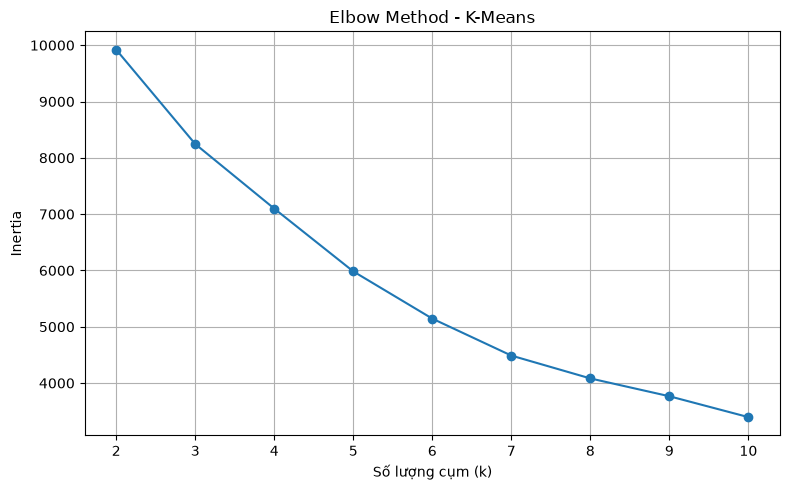

In [68]:
inertia = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker="o"
)

plt.xlabel("Số lượng cụm (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - K-Means")
plt.xticks(K)
plt.grid(True)

os.makedirs("../reports/figures", exist_ok=True)

plt.tight_layout()

plt.savefig(
    "../reports/figures/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 7.1.1. Lựa chọn số lượng cụm

Dựa vào biểu đồ Elbow Method ở trên, xác định vị trí đường cong bắt đầu giảm chậm rõ rệt và lựa chọn giá trị `k` phù hợp.

> **Lưu ý:** Giá trị `optimal_k` bên dưới cần được điều chỉnh theo biểu đồ thực tế sau khi chạy notebook.

In [69]:
# Thay đổi giá trị này theo điểm "khuỷu tay" quan sát được trên biểu đồ
optimal_k = 4

print("Số cụm được lựa chọn:", optimal_k)

Số cụm được lựa chọn: 4


## 7.2. Xây dựng mô hình K-Means

Sau khi xác định số lượng cụm `k`, tiến hành huấn luyện mô hình K-Means trên `X_train`.

**Không sử dụng `y_train` trong bước này.**

In [70]:
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_train)

print("K-Means đã hoàn thành.")
print("Số cụm:", optimal_k)
print("Số lượng mẫu mỗi cụm:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means đã hoàn thành.
Số cụm: 4
Số lượng mẫu mỗi cụm:
0    510
1    582
2    428
3    240
Name: count, dtype: int64


## 7.3. Đánh giá K-Means bằng Silhouette Score

**Silhouette Score** được sử dụng để đánh giá chất lượng các cụm.

Giá trị càng gần `1` cho thấy các cụm càng tách biệt và các điểm dữ liệu trong cùng một cụm càng tương đồng. Giá trị gần `0` cho thấy các cụm có sự chồng lấn, còn giá trị âm cho thấy một số điểm có thể được phân vào cụm chưa phù hợp.

In [71]:
kmeans_score = silhouette_score(X_train, kmeans_labels)
print(f"K-Means Silhouette Score: {kmeans_score:.4f}")

K-Means Silhouette Score: 0.2446


## 7.4. Trực quan hóa K-Means bằng PCA

Do dữ liệu có nhiều đặc trưng nên sử dụng **PCA (Principal Component Analysis)** để giảm dữ liệu xuống không gian 2 chiều.

Biểu đồ Scatter Plot giúp quan sát trực quan cách K-Means phân chia dữ liệu thành các cụm.

Áp dụng PCA để giảm dữ liệu từ không gian đặc trưng ban đầu xuống 2 chiều, phục vụ việc trực quan hóa kết quả phân cụm K-Means.

In [72]:
# Giảm số chiều dữ liệu xuống 2 chiều bằng PCA để trực quan hóa
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

print("X_pca shape:", X_pca.shape)

X_pca shape: (1760, 2)


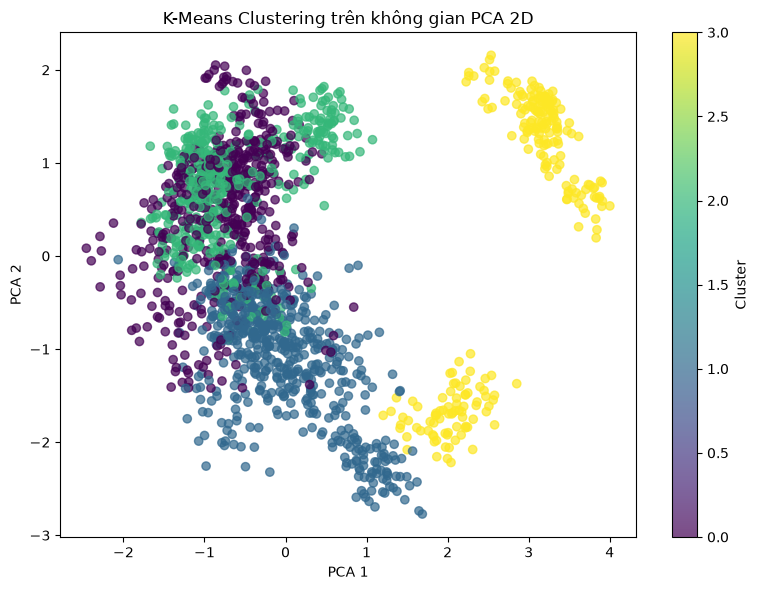

In [73]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("K-Means Clustering trên không gian PCA 2D")
plt.colorbar(label="Cluster")

plt.tight_layout()

plt.savefig(
    "../reports/figures/kmeans_clusters_2d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 8. Hierarchical Clustering

Hierarchical Clustering là phương pháp gom cụm phân cấp, xây dựng các nhóm dữ liệu dựa trên mức độ tương đồng giữa các điểm dữ liệu.

Trong phần này sử dụng **Agglomerative Clustering**. Mô hình bắt đầu từ các điểm riêng lẻ và lần lượt gộp các nhóm gần nhau cho đến khi đạt số lượng cụm được lựa chọn.

Tương tự K-Means, mô hình chỉ sử dụng `X_train` và **không sử dụng nhãn `y` trong quá trình huấn luyện**.

## 8.1. Xây dựng mô hình Hierarchical Clustering

Để so sánh công bằng với K-Means, Hierarchical Clustering sử dụng cùng số lượng cụm `optimal_k` đã lựa chọn ở phần trên.

In [74]:
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_train)

print("Hierarchical Clustering đã hoàn thành.")
print("Số cụm:", optimal_k)
print("Số lượng mẫu mỗi cụm:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Hierarchical Clustering đã hoàn thành.
Số cụm: 4
Số lượng mẫu mỗi cụm:
0    348
1    532
2    720
3    160
Name: count, dtype: int64


## 8.2. Đánh giá Hierarchical Clustering bằng Silhouette Score

Sử dụng Silhouette Score để đánh giá chất lượng các cụm được tạo ra bởi Hierarchical Clustering.

In [75]:
hierarchical_score = silhouette_score(X_train, hierarchical_labels)

print(f"Hierarchical Clustering Silhouette Score: {hierarchical_score:.4f}")

Hierarchical Clustering Silhouette Score: 0.2387


## 8.3. Trực quan hóa Hierarchical Clustering bằng PCA

Sử dụng cùng không gian PCA 2D ở phần K-Means để trực quan hóa kết quả của Hierarchical Clustering.

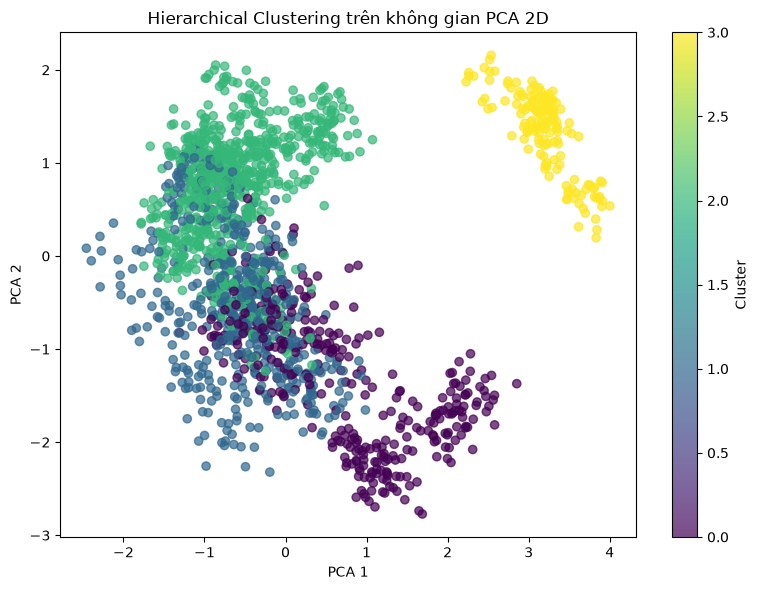

In [76]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Hierarchical Clustering trên không gian PCA 2D")
plt.colorbar(label="Cluster")

plt.tight_layout()

plt.savefig(
    "../reports/figures/hierarchical_clusters_2d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 9. So sánh K-Means và Hierarchical Clustering

Hai thuật toán được đánh giá trên cùng tập dữ liệu `X_train` và sử dụng cùng tiêu chí **Silhouette Score**.

Thuật toán có Silhouette Score cao hơn được xem là có chất lượng phân cụm tốt hơn trên dữ liệu đang xét.

In [77]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical Clustering"],
    "Silhouette Score": [kmeans_score, hierarchical_score]
})

display(comparison)

if kmeans_score > hierarchical_score:
    best_clustering = "K-Means"
elif hierarchical_score > kmeans_score:
    best_clustering = "Hierarchical Clustering"
else:
    best_clustering = "Hai thuật toán có kết quả tương đương"

print(f"Thuật toán có Silhouette Score cao hơn: {best_clustering}")

,Algorithm,Silhouette Score
0,K-Means,0.244638
1,Hierarchical Clustering,0.238686


Thuật toán có Silhouette Score cao hơn: K-Means


## 9.1. Nhận xét kết quả

Dựa trên Silhouette Score, so sánh mức độ tách biệt giữa các cụm của hai thuật toán.

- Silhouette Score của **K-Means**: 0.244638.
- Silhouette Score của **Hierarchical Clustering**: 0.238686.

> Dựa trên Silhouette Score, K-Means đạt 0.244638, trong khi Hierarchical Clustering đạt 0.238686. K-Means có Silhouette Score cao hơn một chút so với Hierarchical Clustering, cho thấy các cụm được tạo bởi K-Means có chất lượng và mức độ phân tách tốt hơn trên tập dữ liệu này.

>Tuy nhiên, sự chênh lệch giữa hai thuật toán là khá nhỏ (0.005952), do đó hiệu quả phân cụm của hai phương pháp là tương đối gần nhau. K-Means được lựa chọn là thuật toán có kết quả tốt hơn theo tiêu chí Silhouette Score.

# 10. Đối chiếu kết quả gom cụm với nhãn thực tế

Sau khi hoàn thành quá trình gom cụm, có thể sử dụng `y_train` để **đối chiếu** với các cluster được tạo ra.

Đây không phải là bước huấn luyện mô hình. Nhãn thực tế chỉ được sử dụng để xem các nhóm dữ liệu tự nhiên có vô tình tương ứng với các loại cây trồng hay không.

## 10.1. Đối chiếu K-Means với nhãn thực tế

Bảng chéo dưới đây cho biết số lượng mẫu thuộc từng loại cây trong mỗi cluster K-Means.

In [78]:
kmeans_vs_actual = pd.crosstab(
    pd.Series(kmeans_labels, name="Cluster"),
    pd.Series(y_train.values, name="Actual Label")
)

display(kmeans_vs_actual)

Actual Label,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,80,56,0,0,80,0,...,0,0,0,0,78,45,9,80,80,0
1,0,0,80,0,0,0,0,0,0,80,...,80,80,80,0,2,0,71,0,0,0
2,0,80,0,0,0,24,80,0,0,0,...,0,0,0,80,0,35,0,0,0,80
3,80,0,0,80,0,0,0,80,0,0,...,0,0,0,0,0,0,0,0,0,0


## 10.2. Đối chiếu Hierarchical Clustering với nhãn thực tế

Bảng chéo dưới đây cho biết số lượng mẫu thuộc từng loại cây trong mỗi cluster Hierarchical Clustering.

In [79]:
hierarchical_vs_actual = pd.crosstab(
    pd.Series(hierarchical_labels, name="Cluster"),
    pd.Series(y_train.values, name="Actual Label")
)

display(hierarchical_vs_actual)

Actual Label,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,80,0,0,0,0,0,80,...,80,32,0,0,0,0,76,0,0,0
1,0,0,80,0,80,0,0,0,0,0,...,0,48,80,0,80,0,4,80,0,0
2,0,80,0,0,0,80,80,0,80,0,...,0,0,0,80,0,80,0,0,80,80
3,80,0,0,0,0,0,0,80,0,0,...,0,0,0,0,0,0,0,0,0,0


# 11. Kết luận

Qua thực nghiệm, K-Means và Hierarchical Clustering được huấn luyện trên các đặc trưng `X_train` mà không sử dụng nhãn `y`.

Số lượng cụm của K-Means được lựa chọn dựa trên Elbow Method. Chất lượng phân cụm của hai thuật toán được đánh giá bằng Silhouette Score và kết quả được trực quan hóa bằng PCA trên không gian 2D.

Sau khi clustering hoàn thành, kết quả được đối chiếu với nhãn thực tế để đánh giá xem các cụm tự nhiên có tương ứng với các loại cây trồng hay không.

**Kết quả cuối cùng cần cập nhật sau khi chạy notebook:**

- K-Means – Optimal k: `4`
- K-Means – Silhouette Score: `0.244638`
- Hierarchical Clustering – Silhouette Score: `0.238686`
- Thuật toán có Silhouette Score cao hơn: `K-Means`
- Nhận xét về mức độ tương đồng giữa cluster và loại cây trồng thực tế: `Các cluster có sự tương ứng khá rõ với một số loại cây trồng, tuy nhiên vẫn tồn tại sự pha trộn giữa các loại cây trong một số cluster.`